# A2 – Felanalys

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from elpris.metrics import SEASONS, bias_by_season, mae_by_season, mae_spike_vs_normal, mae_table

preds_all = pd.read_csv(
    Path("../results/predictions.csv"),
    parse_dates=["forecast_date", "target_date"],
)
print(preds_all.shape)
preds_all["model"].value_counts()

(15540, 7)


model
baseline         7770
random_forest    7770
Name: count, dtype: int64

## 1. MAE per modell och prognosdag

In [3]:
mae_table(preds_all).round(3)

horizon                   1      2      3      4      5      6      7
model         target                                                 
baseline      max     0.569  0.567  0.568  0.567  0.566  0.565  0.569
              mean    0.362  0.361  0.362  0.362  0.362  0.362  0.366
              min     0.270  0.269  0.269  0.268  0.268  0.269  0.270
random_forest max     0.432  0.464  0.466  0.462  0.465  0.483  0.478
              mean    0.270  0.302  0.307  0.308  0.308  0.316  0.313
              min     0.231  0.254  0.259  0.261  0.256  0.257  0.254

## 2. MAE per årstid

In [4]:
mae_by_season(preds_all).round(3)

season                 höst  sommar  vinter    vår
model         target                              
baseline      max     0.765   0.405   0.575  0.515
              mean    0.452   0.303   0.355  0.335
              min     0.312   0.218   0.270  0.273
random_forest max     0.581   0.364   0.498  0.409
              mean    0.346   0.252   0.348  0.266
              min     0.245   0.203   0.344  0.223

## 3. Bias per årstid (negativt = modellen förutsäger för lågt)

In [5]:
bias_by_season(preds_all).round(3)

season                 höst  sommar  vinter    vår
model         target                              
baseline      max     0.052  -0.028   0.021 -0.004
              mean    0.004  -0.018   0.002  0.015
              min     0.008  -0.026  -0.016  0.035
random_forest max     0.055   0.005  -0.094 -0.001
              mean    0.020  -0.023  -0.190 -0.027
              min    -0.014  -0.035  -0.265 -0.008

## 4. RF följer inte prisnivån när den stiger i januari 2026

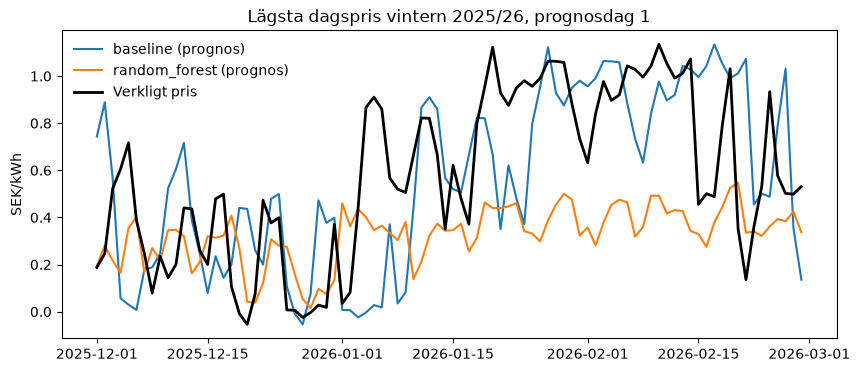

In [6]:
winter = preds_all[
    (preds_all["target"] == "min")
    & (preds_all["horizon"] == 1)
    & (preds_all["target_date"].dt.month.isin([12, 1, 2]))
].sort_values("target_date")

fig, ax = plt.subplots(figsize=(10, 4))
for model, group in winter.groupby("model"):
    ax.plot(group["target_date"], group["y_pred"], label=f"{model} (prognos)")

actual = winter.drop_duplicates("target_date")
ax.plot(actual["target_date"], actual["y_true"], color="black", linewidth=2, label="Verkligt pris")
ax.set_title("Lägsta dagspris vintern 2025/26, prognosdag 1")
ax.set_ylabel("SEK/kWh")
ax.legend(frameon=False);

## 5. Spikdagar jämfört med vanliga dagar

In [7]:
mae_spike_vs_normal(preds_all).round(3)

day_type              normal   spik
model         target               
baseline      max      0.517  1.034
              mean     0.341  0.556
              min      0.251  0.430
random_forest max      0.402  1.040
              mean     0.269  0.620
              min      0.220  0.559

In [8]:
max_rows = preds_all[preds_all["target"] == "max"].drop_duplicates("target_date")
threshold = max_rows["y_true"].quantile(0.9)
spike_days = max_rows[max_rows["y_true"] >= threshold]
spike_days["target_date"].dt.month.map(SEASONS).value_counts()

target_date
höst      16
vinter    12
sommar     8
vår        2
Name: count, dtype: int64